## 1 Two catalogues: uniform and structured

El catálogo estructurado va a tener preferencia por una separación de la escala de radio, es decir, una separación de 30. A esta distancia yo espero que este catálogo presenta más pares que el catálogo uniforme por la densidad de puntos que pueden existir.

A separaciones más pequeñas de 30 en el estructurado, yo esperaría que sea menos probable encontrar pares en el catálogo uniforme.

Sí, la función de correlación puede llegar a valer cero en el catálogo uniforme para algunos casos. Volviendo a la comparación, si escogemos un radio menor a la distancia mínima de separación entre puntos en el catálogo uniforme, entonces la función de correlación siempre será cero en ese caso.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.size'] = 14
SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
NR = 1000
ND = 1000
radius = 30

x_grid, y_grid = np.meshgrid(np.linspace(0, 99, 100), np.linspace(0, 99, 100))

centers = rng.uniform(0, 100, size=(20, 2))
xy_unif = rng.uniform(0, 100, size=(NR, 2))
xy_strc = np.zeros((ND, 2))
for i in range(ND):
    while True:
        p = centers[rng.choice(range(20))]
        angle = rng.uniform(0, 2*np.pi)
        X = p[0] + radius * np.cos(angle)
        Y = p[1] + radius * np.sin(angle)
        if 0 <= X < 100 and 0 <= Y < 100:
            break
    xy_strc[i] = [X, Y]


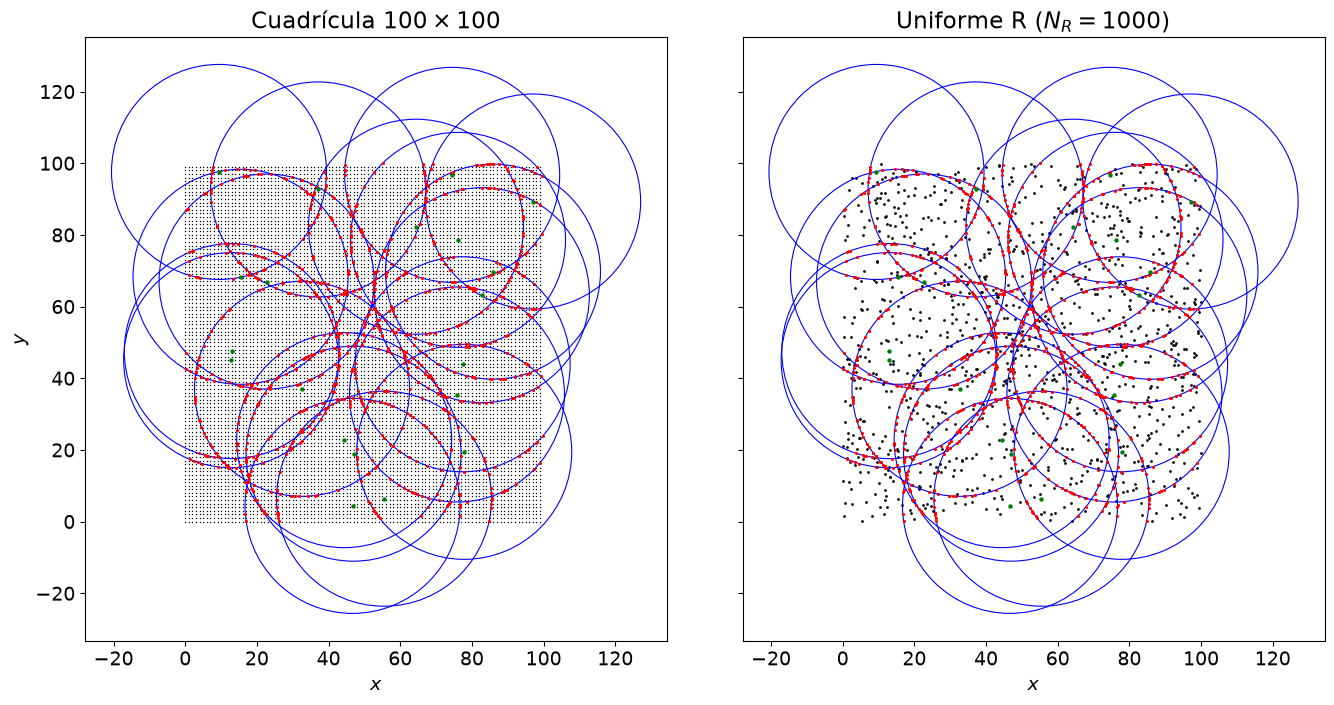

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
fondos = [((x_grid, y_grid), 1, 'Cuadrícula $100\\times100$'),
          (xy_unif.T, 4, f'Uniforme R ($N_R={NR}$)')]
for ax, (fondo, s, titulo) in zip(axs, fondos):
    ax.scatter(*fondo, s=s, c='k', linewidths=0, zorder=1)
    for p in centers:
        ax.add_patch(plt.Circle(p, radius, fill=False, ec='b', lw=0.8, zorder=2))
    ax.scatter(*xy_strc.T, s=5, c='r', linewidths=0, zorder=3)
    ax.scatter(*centers.T, s=10, c='g', linewidths=0, zorder=4)
    ax.set(xlabel='$x$', title=titulo, aspect='equal')
axs[0].set_ylabel('$y$')
fig.tight_layout()
plt.show()

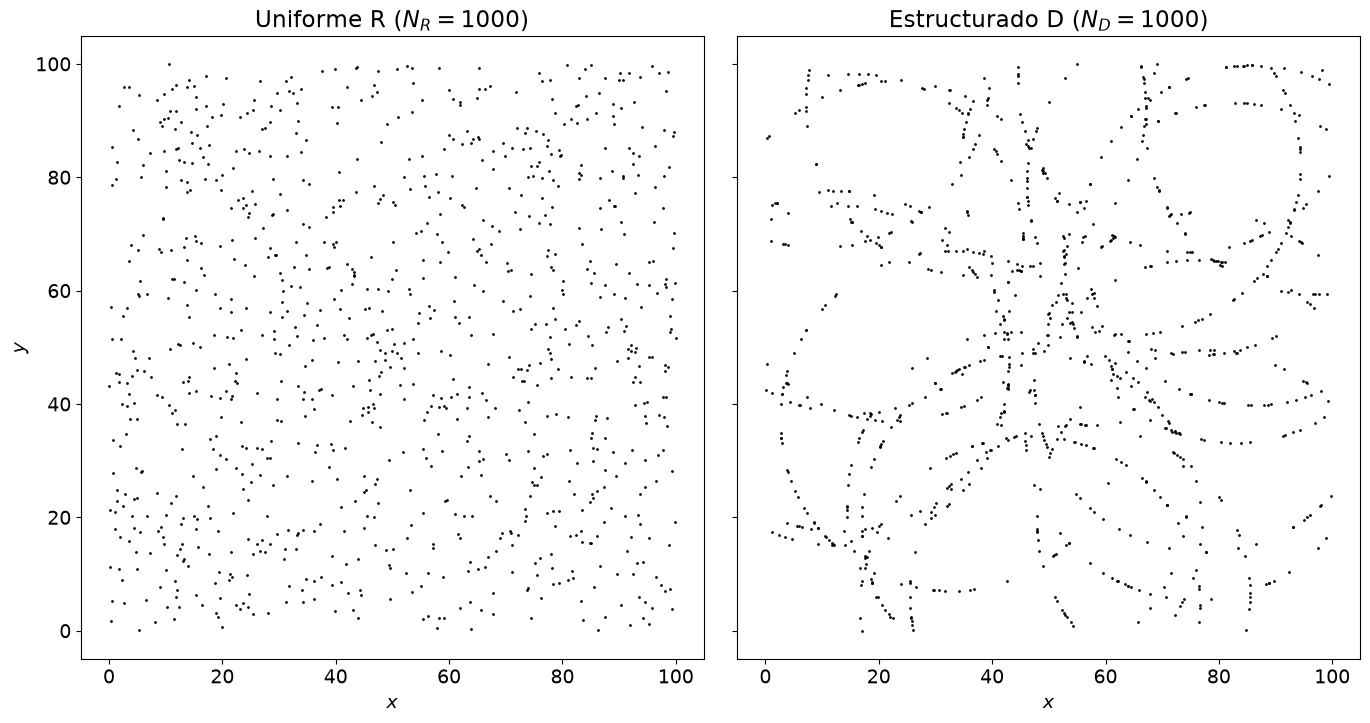

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
ax1.scatter(*xy_unif.T, s=4, c='k', linewidths=0)
ax2.scatter(*xy_strc.T, s=4, c='k', linewidths=0)
ax1.set(xlabel='$x$', ylabel='$y$', title=f'Uniforme R ($N_R={NR}$)', aspect='equal')
ax2.set(xlabel='$x$', title=f'Estructurado D ($N_D={ND}$)', aspect='equal')
fig.tight_layout()
plt.show()

## 2 Compute pairs

In [5]:
from scipy.spatial.distance import pdist

edges = np.linspace(0, 100*np.sqrt(2), 51)
DD, _ = np.histogram(pdist(xy_strc), bins=edges)
RR, _ = np.histogram(pdist(xy_unif), bins=edges)

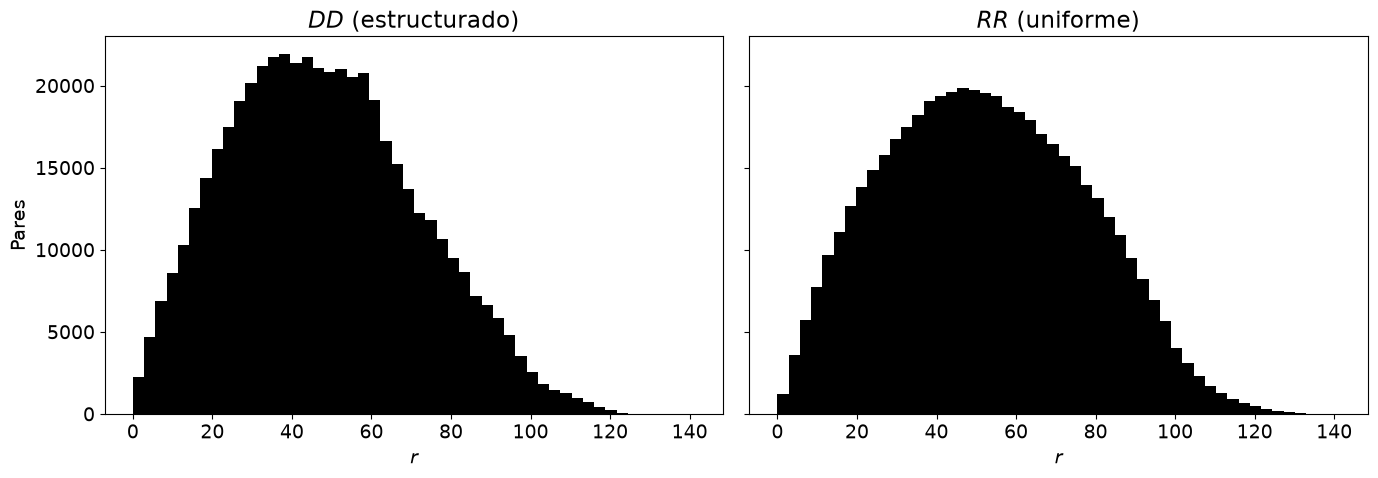

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, H, t in zip(axs, (DD, RR), ('$DD$ (estructurado)', '$RR$ (uniforme)')):
    ax.stairs(H, edges, fill=True, color='k')
    ax.set(xlabel='$r$', title=t)
axs[0].set_ylabel('Pares')
fig.tight_layout()
plt.show()

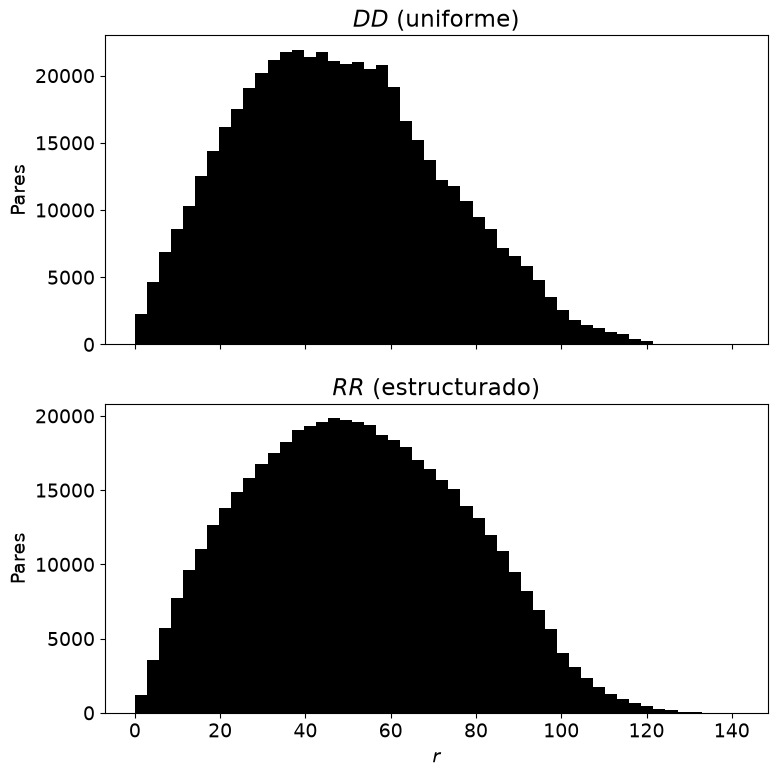

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
for ax, H, t in zip(axs, (DD, RR), ('$DD$ (uniforme)', '$RR$ (estructurado)')):
    ax.stairs(H, edges, fill=True, color='k')
    ax.set(ylabel='Pares', title=t)
axs[1].set_xlabel('$r$')
fig.tight_layout()
plt.show()